In [1]:
from anemone.forwards import Forward, rte, c
from anemone.system import *
import torch
import matplotlib.pyplot as plt
import numpy as np


torch detected, enabling torch tensor support in nosj


In [2]:
class Forward2(Forward):
    def forward(self):
        if self.H2t is None: self.setup()
        with torch.no_grad():
            self.cRTE = rte(self.sigma, self.thick, self.omega, self.lamda).squeeze()
            res = torch.einsum('ik,...k->i...', self.H2t, self.cRTE)#.real
            if len(res.shape)>1: res = res.mT
            return res

In [3]:
#fwr = Forward2.example(tolerance=1e-3)
tx = Loop.square(40)
rx = Receiver()
t = torch.logspace(-7, -2, 51)
fwr = Forward2(tx,rx,t, tolerance=1e-3)

rho = torch.tensor([10, 30, 50])
thk = torch.tensor([20, 20])

dbdt = fwr(rho, thk)

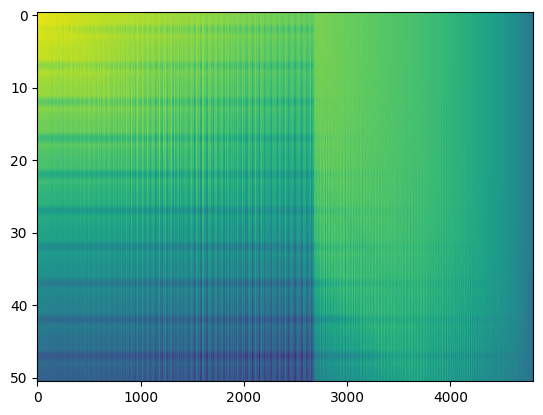

In [4]:
plt.figure()
plt.imshow(torch.log10(torch.abs(fwr.H2t.real)), aspect='auto')

In [5]:
from numpy.linalg import pinv

In [17]:
iH2t = pinv(fwr.H2t.real.numpy().T).T

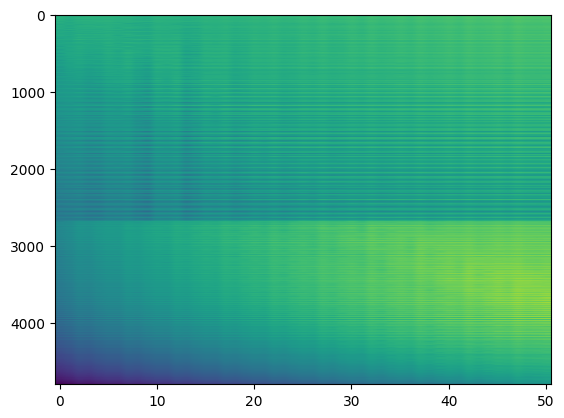

In [18]:
plt.figure()
plt.imshow(np.log10(np.abs(iH2t.real)), aspect='auto')

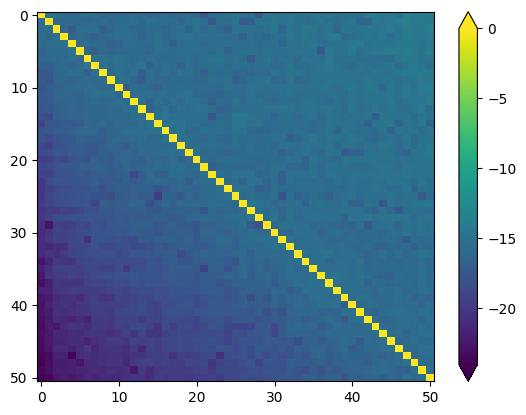

In [20]:
I = fwr.H2t.real.numpy()@iH2t
plt.figure()
pcm=plt.imshow(np.log10(np.abs(I)), aspect='auto')
plt.colorbar(pcm, extend='both')

In [22]:
crte = iH2t @ (dbdt.numpy()/c.mu0)

C:\Users\au646858\AppData\Local\Temp\ipykernel_23024\3785033325.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  dbdt0 = fwr.H2t.real @ crte * c.mu0
c:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\.venv\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\.venv\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


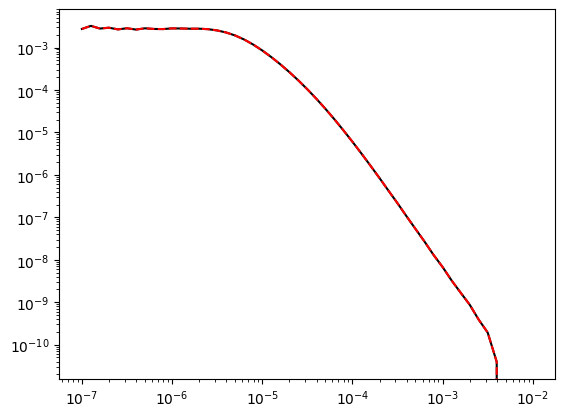

In [23]:
dbdt0 = fwr.H2t.real @ crte * c.mu0
plt.figure()
plt.loglog(fwr.times, dbdt.numpy().flatten(), 'k-')
plt.loglog(fwr.times, dbdt0.flatten(), 'r--')

(1000.0, 1200.0)

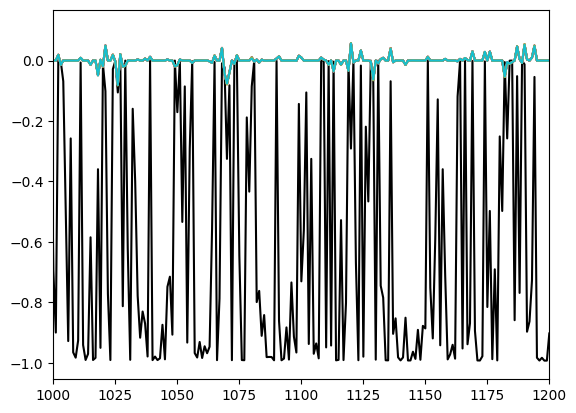

In [24]:
plt.figure()
plt.plot(fwr.cRTE.real, 'k-')

for i in range(10):
    cdbdt = dbdt.numpy()+0.03*dbdt.numpy()*np.random.randn(*dbdt.numpy().shape)
    crte = iH2t @ (-cdbdt.real/c.mu0)
    plt.plot(crte.real)
plt.xlim(1000, 1200)


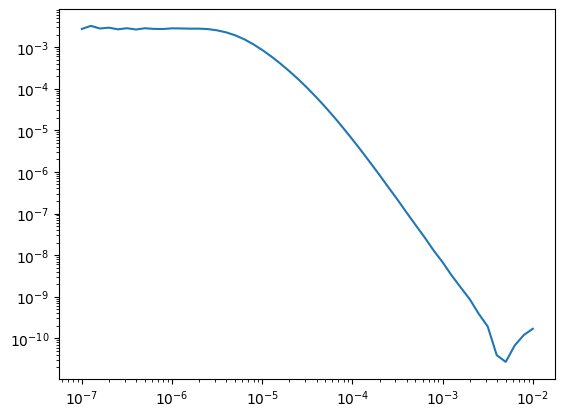

In [25]:
plt.figure()
plt.loglog(fwr.times, torch.abs(dbdt.real))